# Cointegração e correção de erros — R e Python

**EAD6034 · exercício resolvido · 23/11/2026**

**Pergunta:** duas séries podem variar persistentemente e, ainda assim, manter uma relação estável entre si? E, quando se afastam dessa relação, qual delas se ajusta?

Na **Parte A**, conhecemos a resposta porque construímos os dados: $y_t=3x_t+z_t$, com $z_t=0{,}6z_{t-1}+\varepsilon_t$. Na **Parte B**, investigamos juros americanos de 1 e 5 anos com dados históricos do pacote `tseries`.

Este arquivo já contém tabelas e gráficos, para leitura no GitHub. Para executar, abra no **Codespaces**, selecione o kernel **Python 3 (EAD6034 — Cointegração)** e clique em **Run All**. Veja também o [script R](exercicio_cointegracao.R) e o [resumo](README.md).

**Convenções:** *aula* identifica a especificação do roteiro fornecido; *implementação* identifica cuidados para a equivalência entre linguagens; *esclarecimento conceitual* delimita a interpretação. O objetivo aqui é reproduzir o exercício, com os testes que ele solicita.

## 0. Preparação e dados comuns

**Implementação.** A simulação foi gerada em R com `set.seed(10)` e exportada com 17 algarismos significativos. Python lê as mesmas observações: sementes iguais em linguagens diferentes não garantem os mesmos sorteios. Os dados históricos também estão no repositório, sem downloads durante a análise.

Os cálculos abaixo são executados em Python. O módulo [`cointegracao.py`](cointegracao.py) expõe os mínimos quadrados, o ADF com as convenções de `ur.df` e o teste de Johansen com constante restrita. Nenhuma estimativa R é usada como entrada da estimação Python.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Funciona com o kernel iniciado na pasta do exercício ou na raiz do repositório.
candidates = [candidate for parent in [Path.cwd(), *Path.cwd().parents]
              for candidate in [parent, parent / "exercicio-cointegracao"]]
folder = next((p for p in candidates if (p / "cointegracao.py").is_file()), None)
if folder is None:
    raise FileNotFoundError("Abra o notebook no repositório EAD6034 ou na pasta do exercício.")
sys.path.insert(0, str(folder))
from cointegracao import ols, adf_urca, engle_granger_ecm, johansen_restricted_constant, analyze
from validacao import comparar, salvar_resultados

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.18, "font.size": 10})
blue, orange = "#174C70", "#C35831"
pd.set_option("display.max_columns", 8)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

sim = pd.read_csv(folder / "data/simulacao.csv", float_precision="round_trip")
juros = pd.read_csv(folder / "data/juros.csv", parse_dates=["date"], float_precision="round_trip")
x, y = sim["x"].to_numpy(), sim["y"].to_numpy()
rates = juros[["media", "curta"]].to_numpy()
display(Markdown(f"**Dados carregados:** {len(sim)} observações simuladas e {len(juros)} observações mensais de juros, de {juros['date'].min():%m/%Y} a {juros['date'].max():%m/%Y}. Taxas expressas em **% ao ano**; diferenças de taxas em **pontos percentuais**."))

**Dados carregados:** 300 observações simuladas e 558 observações mensais de juros, de 04/1953 a 09/1999. Taxas expressas em **% ao ano**; diferenças de taxas em **pontos percentuais**.

## Parte A — sabemos que existe uma relação de longo prazo

### P1–P2. As séries se movem juntas? A distância é estável?

**Aula.** $x$ é um passeio aleatório. $y$ contém três vezes esse passeio, mais um erro que tende a retornar a zero. A comparação visual relevante é entre $y$ e $3x$.

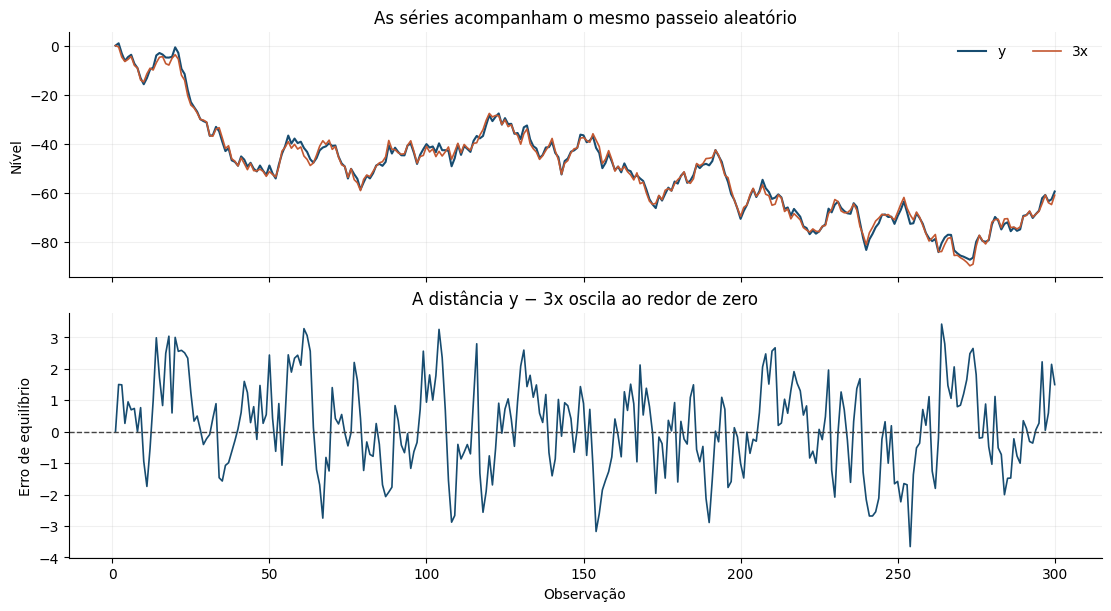

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
axes[0].plot(sim["t"], y, color=blue, linewidth=1.5, label="y")
axes[0].plot(sim["t"], 3*x, color=orange, linewidth=1.2, label="3x")
axes[0].set(title="As séries acompanham o mesmo passeio aleatório", ylabel="Nível")
axes[0].legend(frameon=False, ncol=2)
axes[1].plot(sim["t"], y-3*x, color=blue, linewidth=1.2)
axes[1].axhline(0, color="#444444", linestyle="--", linewidth=1)
axes[1].set(title="A distância y − 3x oscila ao redor de zero", xlabel="Observação", ylabel="Erro de equilíbrio")
plt.show()

**Respostas P1–P2.** As séries em nível não têm uma média fixa, mas andam juntas. A distância é o processo estacionário $z$: ela oscila ao redor de zero, como uma distância limitada por uma coleira. Isso é a ideia de **cointegração**: uma combinação de séries não estacionárias pode ser estacionária.

### P3–P4. Estimar a relação e testar seu erro

**Aula.** Primeiro estimamos $y=a+bx+u$; depois aplicamos o ADF aos resíduos, sem constante e com uma defasagem. A decisão usa o crítico de **Engle–Granger de −3,34**, fornecido no exercício. O crítico ADF usual não é apropriado para resíduos de uma relação estimada.

In [3]:
passo1 = ols(y, np.column_stack([np.ones(len(x)), x]))
residuo = passo1.residuals
teste_eg = adf_urca(residuo, regression="none", max_lags=1, select_lags="Fixed")
critico_eg = -3.34
display(passo1.table(["constante", "x"]))
display(pd.DataFrame({"estatistica": [teste_eg.statistic], "critico_5pct": [critico_eg],
                      "cointegracao_5pct": [teste_eg.statistic < critico_eg]}, index=["Engle–Granger"]))
display(Markdown(f"**P3:** coeficiente de x = **{passo1.params[1]:.6f}**, próximo do verdadeiro 3. **P4:** {teste_eg.statistic:.4f} < −3,34; rejeitamos ausência de cointegração nesta simulação."))

,coeficiente,erro_padrao,estatistica_t
constante,0.592391,0.229159,2.585063
x,3.025099,0.012644,239.254173


,estatistica,critico_5pct,cointegracao_5pct
Engle–Granger,-7.746862,-3.340000,True


**P3:** coeficiente de x = **3.025099**, próximo do verdadeiro 3. **P4:** -7.7469 < −3,34; rejeitamos ausência de cointegração nesta simulação.

### P5–P6. Quanto do desequilíbrio se corrige?

**Aula.** O ECM é $\Delta y_t=c+\alpha\hat u_{t-1}+\gamma\Delta x_t+e_t$. Pela construção dos dados, $\alpha=\rho-1=0{,}6-1=-0{,}4$.

In [4]:
dy, dx = np.diff(y), np.diff(x)
z_lag = residuo[:-1]
ecm = ols(dy, np.column_stack([np.ones(len(dy)), z_lag, dx]))
display(ecm.table(["constante", "erro_equilibrio_lag1", "dx"]))
display(Markdown(f"**P5:** α teórico = **−0,4**; α estimado = **{ecm.params[1]:.6f}**. A diferença é variação amostral. **P6:** se y está 10 unidades acima do equilíbrio, a contribuição da correção é **−4 unidades** no modelo verdadeiro, ou **{10*ecm.params[1]:.3f} unidades** no modelo estimado, no período seguinte. A variação total ainda inclui Δx, constante e inovação."))

,coeficiente,erro_padrao,estatistica_t
constante,-0.008827,0.062504,-0.141226
erro_equilibrio_lag1,-0.378020,0.044705,-8.455914
dx,2.822441,0.064935,43.465458


**P5:** α teórico = **−0,4**; α estimado = **-0.378020**. A diferença é variação amostral. **P6:** se y está 10 unidades acima do equilíbrio, a contribuição da correção é **−4 unidades** no modelo verdadeiro, ou **-3.780 unidades** no modelo estimado, no período seguinte. A variação total ainda inclui Δx, constante e inovação.

## Parte B — juros americanos de 1 e 5 anos

**Aula.** Usamos `tseries::tcm`: taxas de vencimento constante, mensais, de abril/1953 a setembro/1999. A documentação do pacote atribui os dados ao **Federal Reserve H.15**. O snapshot histórico é o mesmo do exercício; não é uma atualização das taxas atuais. [Fonte do dataset](https://search.r-project.org/CRAN/refmans/tseries/html/tcm.html).

### P7. O gráfico sugere uma relação?

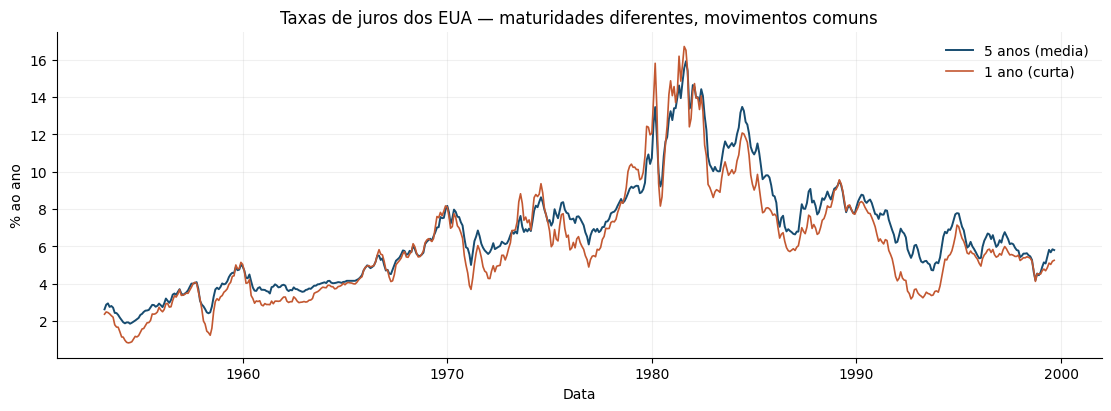

In [5]:
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
ax.plot(juros["date"], juros["media"], color=blue, linewidth=1.4, label="5 anos (media)")
ax.plot(juros["date"], juros["curta"], color=orange, linewidth=1.2, label="1 ano (curta)")
ax.set(title="Taxas de juros dos EUA — maturidades diferentes, movimentos comuns", xlabel="Data", ylabel="% ao ano")
ax.legend(frameon=False)
plt.show()

**P7.** As taxas acompanham movimentos comuns, embora a diferença varie. Isso motiva o teste de cointegração; o gráfico, sozinho, não o substitui.

### P8. As séries são compatíveis com I(1)?

**Aula.** Testamos cada taxa em nível e em primeira diferença, com constante. Rejeitamos a hipótese de raiz unitária quando a estatística é **menor** que o crítico.

**Implementação.** Para reproduzir `ur.df(..., lags=6, selectlags="AIC")`, comparamos **1 a 6** defasagens e mantemos a mesma amostra, cortada pelo máximo de 6. A chamada padrão de `statsmodels.adfuller` usa convenções diferentes. O número selecionado é mostrado na tabela.

In [6]:
adfs = {
    "5 anos — nível": adf_urca(rates[:, 0]),
    "1 ano — nível": adf_urca(rates[:, 1]),
    "5 anos — diferença": adf_urca(np.diff(rates[:, 0])),
    "1 ano — diferença": adf_urca(np.diff(rates[:, 1])),
}
tabela_adf = pd.DataFrame.from_dict({name: {
    "estatistica": test.statistic, "critico_5pct": test.critical_5pct,
    "defasagens_AIC": test.lags, "observacoes": test.nobs,
    "rejeita_raiz_unitaria": test.reject_unit_root_5pct,
} for name, test in adfs.items()}, orient="index")
display(tabela_adf)
assert not adfs["5 anos — nível"].reject_unit_root_5pct
assert not adfs["1 ano — nível"].reject_unit_root_5pct
assert adfs["5 anos — diferença"].reject_unit_root_5pct
assert adfs["1 ano — diferença"].reject_unit_root_5pct
display(Markdown("**P8:** não rejeitamos a raiz unitária nos níveis; rejeitamos nas diferenças. O padrão é **compatível com ambas as séries I(1)**. Não rejeitar uma hipótese não significa demonstrá-la."))

,estatistica,critico_5pct,defasagens_AIC,observacoes,rejeita_raiz_unitaria
5 anos — nível,-1.892208,-2.860000,6,551,False
1 ano — nível,-2.021130,-2.860000,6,551,False
5 anos — diferença,-10.432675,-2.860000,5,550,True
1 ano — diferença,-11.915546,-2.860000,5,550,True


**P8:** não rejeitamos a raiz unitária nos níveis; rejeitamos nas diferenças. O padrão é **compatível com ambas as séries I(1)**. Não rejeitar uma hipótese não significa demonstrá-la.

### P9–P11. Quantas relações de cointegração existem?

**Aula.** Johansen, teste do traço, `K=2`, constante restrita à relação de longo prazo e especificação `transitory`. Duas defasagens em níveis equivalem a **uma diferença defasada** no VECM. Aqui rejeitamos quando a estatística é **maior** que o crítico.

**Implementação.** O cálculo matricial em Python conserva a constante dentro do vetor de níveis defasados. Usar simplesmente `coint_johansen(det_order=0)` não reproduziria esta especificação. A tabela abaixo está na ordem de leitura: primeiro $r=0$, depois $r\leq1$.

In [7]:
jo = johansen_restricted_constant(rates, K=2)
display(jo.trace_table())
assert jo.rank_5pct == 1, "Reavalie a interpretação: o posto selecionado mudou."
display(Markdown(f"**P9:** {jo.trace_statistics[0]:.4f} > 19,96: rejeitamos r=0. **P10:** {jo.trace_statistics[1]:.4f} < 9,24: não rejeitamos r≤1. **P11:** selecionamos **uma relação de cointegração**, ao nível de 5%."))

,estatistica,critico_10pct,critico_5pct,critico_1pct,rejeita_5pct
r = 0,35.091827,17.850000,19.960000,24.600000,True
r <= 1,5.457753,7.520000,9.240000,12.970000,False


**P9:** 35.0918 > 19,96: rejeitamos r=0. **P10:** 5.4578 < 9,24: não rejeitamos r≤1. **P11:** selecionamos **uma relação de cointegração**, ao nível de 5%.

### P12–P13. Qual é a relação de longo prazo?

O vetor é normalizado pelo coeficiente da taxa de 5 anos: $\text{media}+b\,\text{curta}+c=0$. Para escrever `media` isolada, trocamos os sinais de $b$ e $c$.

In [8]:
display(pd.DataFrame({"beta": jo.beta}, index=["media (5 anos)", "curta (1 ano)", "constante"]))
intercepto, inclinacao = -jo.beta[2], -jo.beta[1]
display(Markdown(f"**P12:** taxa de 5 anos ≈ **{intercepto:.6f} + {inclinacao:.6f} × taxa de 1 ano**. **P13:** na relação estimada, uma diferença de 1 ponto percentual na taxa de 1 ano corresponde a cerca de **{inclinacao:.3f} ponto percentual** na taxa de 5 anos, no longo prazo. É uma relação estatística, sem identificação de causalidade."))

,beta
media (5 anos),1.000000
curta (1 ano),-1.037094
constante,-0.357076


**P12:** taxa de 5 anos ≈ **0.357076 + 1.037094 × taxa de 1 ano**. **P13:** na relação estimada, uma diferença de 1 ponto percentual na taxa de 1 ano corresponde a cerca de **1.037 ponto percentual** na taxa de 5 anos, no longo prazo. É uma relação estatística, sem identificação de causalidade.

### P14–P15. Quem se ajusta quando há um desvio?

O termo de erro é $ECT=\text{media}+b\,\text{curta}+c$. Um ECT positivo significa que a taxa de 5 anos está acima da relação estimada. Cada equação tem seu próprio coeficiente de correção $\alpha$.

**Aula.** Mantemos a regra didática `|t| > 2`. **Implementação.** Os erros padrão são os OLS condicionais usados por `cajorls`, com divisor $n-k$. Eles não são os mesmos erros padrão assintóticos de máxima verossimilhança do VECM no statsmodels.

,alpha,erro_padrao,estatistica_t,reage_pelo_criterio_da_aula
5 anos,0.003718,0.017444,0.213131,False
1 ano,0.063300,0.023700,2.670827,True


**P14:** pelo critério do roteiro, reage(m) a(s) taxa(s) de **1 ano**. **P15:** para ECT=+1 ponto percentual, o componente de correção no mês seguinte é **+0.00372 p.p.** na taxa de 5 anos e **+0.06330 p.p.** na taxa de 1 ano. A direção do ajuste é dada pelos sinais; as demais diferenças defasadas e os novos choques também afetam o movimento observado.

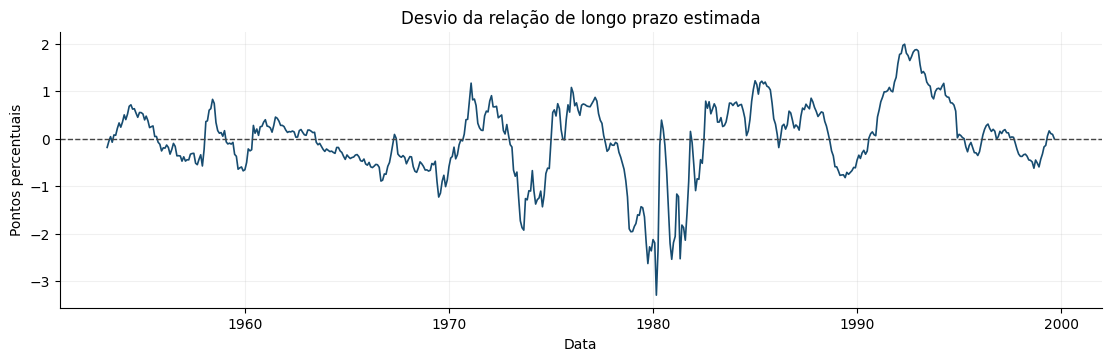

Nesta amostra, **a taxa de 1 ano tende a subir quando o ECT é positivo**, reduzindo o desvio. Não há evidência estatística clara de que a taxa de 5 anos faça a correção.

In [9]:
tabela_ajuste = pd.DataFrame({
    "alpha": jo.alpha, "erro_padrao": jo.vecm.stderr[0, :],
    "estatistica_t": jo.alpha_tvalues, "reage_pelo_criterio_da_aula": np.abs(jo.alpha_tvalues) > 2,
}, index=["5 anos", "1 ano"])
display(tabela_ajuste)
reagem = [name for name, t in zip(["5 anos", "1 ano"], jo.alpha_tvalues) if abs(t) > 2]
display(Markdown(f"**P14:** pelo critério do roteiro, reage(m) a(s) taxa(s) de **{', '.join(reagem) if reagem else 'nenhuma maturidade'}**. **P15:** para ECT=+1 ponto percentual, o componente de correção no mês seguinte é **{jo.alpha[0]:+.5f} p.p.** na taxa de 5 anos e **{jo.alpha[1]:+.5f} p.p.** na taxa de 1 ano. A direção do ajuste é dada pelos sinais; as demais diferenças defasadas e os novos choques também afetam o movimento observado."))

fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
erro_equilibrio = np.column_stack([rates, np.ones(len(rates))]) @ jo.beta
ax.plot(juros["date"], erro_equilibrio, color=blue, linewidth=1.2)
ax.axhline(0, color="#444444", linestyle="--", linewidth=1)
ax.set(title="Desvio da relação de longo prazo estimada", xlabel="Data", ylabel="Pontos percentuais")
plt.show()
display(Markdown("Nesta amostra, **a taxa de 1 ano tende a subir quando o ECT é positivo**, reduzindo o desvio. Não há evidência estatística clara de que a taxa de 5 anos faça a correção."))

## Desafios D1 e D2

**D1 — retirar a correção da simulação.** Alteramos somente $\rho$ de 0,6 para 1, preservando os mesmos choques. Agora $z$ também é um passeio aleatório: a distância pode se afastar persistentemente de zero.

**D2 — diferença simples entre os juros.** Testamos `media − curta` com o mesmo ADF. Isso usa coeficiente unitário; o vetor livre de Johansen estima seu próprio coeficiente.

,estatistica,critico_5pct,rejeita_hipotese_nula
D1: EG com rho=1 (H0: sem cointegração),-2.757567,-3.340000,False
D2: ADF do spread (H0: raiz unitária),-3.204794,-2.860000,True


**D1:** estatística -2.7576; o teste não indica cointegração a 5%, coerentemente com a retirada da correção. **D2:** estatística -3.2048; rejeitamos raiz unitária no spread simples. A restrição de coeficiente exatamente igual a 1 não foi formalmente testada no Johansen; estes resultados não demonstram essa igualdade.

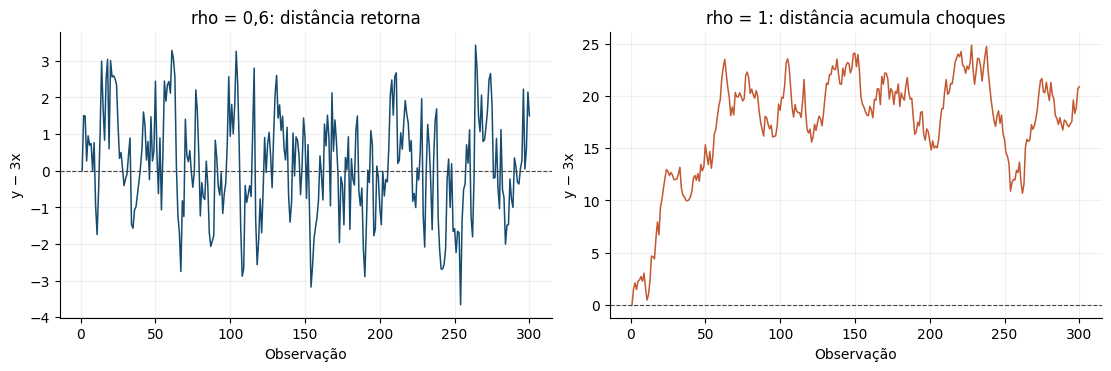

In [10]:
d1 = engle_granger_ecm(x, sim["y_rho1"].to_numpy())
d2 = adf_urca(rates[:, 0] - rates[:, 1])
display(pd.DataFrame({
    "estatistica": [d1.eg_adf.statistic, d2.statistic],
    "critico_5pct": [d1.critical_5pct, d2.critical_5pct],
    "rejeita_hipotese_nula": [d1.cointegrated_5pct, d2.reject_unit_root_5pct],
}, index=["D1: EG com rho=1 (H0: sem cointegração)", "D2: ADF do spread (H0: raiz unitária)"]))
assert not d1.cointegrated_5pct
display(Markdown(f"**D1:** estatística {d1.eg_adf.statistic:.4f}; o teste não indica cointegração a 5%, coerentemente com a retirada da correção. **D2:** estatística {d2.statistic:.4f}; {'rejeitamos' if d2.reject_unit_root_5pct else 'não rejeitamos'} raiz unitária no spread simples. A restrição de coeficiente exatamente igual a 1 não foi formalmente testada no Johansen; estes resultados não demonstram essa igualdade."))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
axes[0].plot(sim["t"], sim["z"], color=blue, linewidth=1.1)
axes[1].plot(sim["t"], sim["z_rho1"], color=orange, linewidth=1.1)
for ax, title in zip(axes, ["rho = 0,6: distância retorna", "rho = 1: distância acumula choques"]):
    ax.axhline(0, color="#444444", linestyle="--", linewidth=0.8)
    ax.set(title=title, xlabel="Observação", ylabel="y − 3x")
plt.show()

## Verificação independente e comparação com R

**Implementação.** Como conferência adicional, o `statsmodels` calcula Engle–Granger com uma defasagem e estima o VECM com `deterministic="ci"`. Comparamos estatística EG e coeficientes. Não misturamos valores críticos de especificações diferentes nem os dois tipos de erro padrão.

In [11]:
from statsmodels.tsa.stattools import coint
from statsmodels.tsa.vector_ar.vecm import VECM

sm_eg = coint(y, x, trend="c", maxlag=1, autolag=None)
sm_vecm = VECM(rates, k_ar_diff=1, coint_rank=1, deterministic="ci").fit()
sm_beta = np.r_[sm_vecm.beta[:, 0], sm_vecm.det_coef_coint[:, 0]]
np.testing.assert_allclose(teste_eg.statistic, sm_eg[0], atol=1e-8, rtol=1e-8)
np.testing.assert_allclose(jo.beta, sm_beta, atol=1e-8, rtol=1e-8)
np.testing.assert_allclose(jo.alpha, sm_vecm.alpha[:, 0], atol=1e-8, rtol=1e-8)
np.testing.assert_allclose(jo.vecm.params[1:, :].T, sm_vecm.gamma, atol=1e-8, rtol=1e-8)
print("Conferência independente com statsmodels: estatística EG, beta, alpha e dinâmica de curto prazo conferem.")

Conferência independente com statsmodels: estatística EG, beta, alpha e dinâmica de curto prazo conferem.


### Comparação R × Python

O CSV R foi produzido executando [`exercicio_cointegracao.R`](exercicio_cointegracao.R). Esta célula recalcula as métricas Python e confere **todas as chaves**, não apenas os números arredondados. Tolerância: `|Python − R| ≤ 1e−8 + 1e−8 × |R|`.

O notebook pode ser executado sem R, comparando com a referência R já salva. Para reexecutar **as duas linguagens**, use `python scripts/reproduzir.py` dentro desta pasta. A tabela completa, a incerteza dos coeficientes e os hashes ficam em [`resultados/`](resultados/).

In [12]:
results = analyze(folder)
comparison = comparar(folder, results["metrics"])
manifest = salvar_resultados(folder, results, comparison)
principais = ["A.ols.slope", "A.eg.stat", "A.ecm.alpha",
              "B.johansen.r0.trace", "B.johansen.r1.trace", "B.rank5",
              "B.beta.curta", "B.beta.const", "B.alpha.media", "B.alpha.curta",
              "B.alpha_t.media", "B.alpha_t.curta", "D1.eg.stat", "D2.spread.stat"]
display(comparison.set_index("key").loc[principais, ["R", "Python", "erro_absoluto", "confere"]])
display(Markdown(f"**Validação concluída:** {len(comparison)}/{len(comparison)} métricas conferem. Maior diferença absoluta: **{comparison['erro_absoluto'].max():.3e}**. Resultados salvos com a precisão completa; apenas a exibição está arredondada."))

,R,Python,erro_absoluto,confere
key,,,,
A.ols.slope,3.025099,3.025099,0.000000,True
A.eg.stat,-7.746862,-7.746862,0.000000,True
A.ecm.alpha,-0.378020,-0.378020,0.000000,True
B.johansen.r0.trace,35.091827,35.091827,0.000000,True
B.johansen.r1.trace,5.457753,5.457753,0.000000,True
B.rank5,1.000000,1.000000,0.000000,True
B.beta.curta,-1.037094,-1.037094,0.000000,True
B.beta.const,-0.357076,-0.357076,0.000000,True
B.alpha.media,0.003718,0.003718,0.000000,True


**Validação concluída:** 52/52 métricas conferem. Maior diferença absoluta: **4.015e-12**. Resultados salvos com a precisão completa; apenas a exibição está arredondada.

## Conclusão em poucas linhas

A simulação mostra a ideia central: duas séries podem se deslocar juntas sem média fixa, enquanto sua distância retorna ao equilíbrio. O ECM mede a correção desse desvio. Quando retiramos esse mecanismo no desafio, o teste deixa de indicar cointegração.

Nas taxas históricas americanas, o padrão dos testes é compatível com séries I(1), e a especificação de Johansen do roteiro seleciona uma relação de longo prazo. O ajuste estatisticamente significativo está na **taxa de 1 ano, que tende a subir quando a taxa de 5 anos está acima da relação estimada**. Não há evidência clara de correção pela taxa de 5 anos. Isso não implica uma relação causal nem garante que os mesmos parâmetros descrevam os juros atuais.

### Fontes e convenções

- [Dataset `tseries::tcm`](https://search.r-project.org/CRAN/refmans/tseries/html/tcm.html).
- [ADF: código original de `ur.df`](https://github.com/cran/urca/blob/master/R/ur-df.R).
- [Johansen: código original de `ca.jo`](https://github.com/cran/urca/blob/master/R/ca-jo.R).
- [VECM OLS: código original de `cajorls`](https://github.com/cran/urca/blob/master/R/cajorls.R).
- [statsmodels: VECM e termos determinísticos](https://www.statsmodels.org/stable/generated/statsmodels.tsa.vector_ar.vecm.VECM.html).
- [GitHub: renderização estática de notebooks](https://docs.github.com/en/repositories/working-with-files/using-files/working-with-non-code-files#working-with-jupyter-notebook-files-on-github).